# Teriparatide — repeated SC dosing and variability

 20 µg SC once daily for 30 days, this time 100 simulated patients (with varying ).

Based on the [first PK notebook](teriparatide_pk_basics.ipynb) and [FDA label, Section 12.3](https://www.accessdata.fda.gov/drugsatfda_docs/label/2024/021318s057lbl.pdf).

The absorption constant and variability ranges are explatory, not fitted patient data.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rcParams["figure.figsize"] = (7, 3.5)

### Model parameters

- **dose:** Drug amount per injection
- **weight:** Patient body weight
- **vd_per_kg:** Apparent distribution volume per kg
- **cl:** Clearance; volume in plasma cleared per hour
- **F:** Bioavailability; fraction reaching circulation
- **ka:** Absorption rate constant
- **interval:** Time between injections
- **n_doses:** Total number of injections

### Calculated parameters

- **vd:** Total apparent distribution volume
- **kel:** Elimination rate constant

subcutaneously (SC)
intravenous (IV)

## 2. Parameters

Same values as Model 1. Here `ka` is slower than `kel`, so absorption controls the late SC decline.

In [2]:
dose = 20.0          # µg
weight = 70.0        # kg
vd_per_kg = 0.12     # L/kg, IV estimate
cl = 60.0            # L/h, women
F = 0.90             # SC bioavailability
ka = 0.693           # 1/h, assumed
interval = 24.0      # hours
n_doses = 30

vd = vd_per_kg * weight
kel = cl / vd # Elimination rate (1/h)
print(f"Vd: {vd:.2f} L | kel: {kel:.2f} 1/h")

Vd: 8.40 L | kel: 7.14 1/h


## 3. Single dose → repeated doses

Add the concentration from each earlier injection. The model assumes the same dose and constant PK parameters throughout.

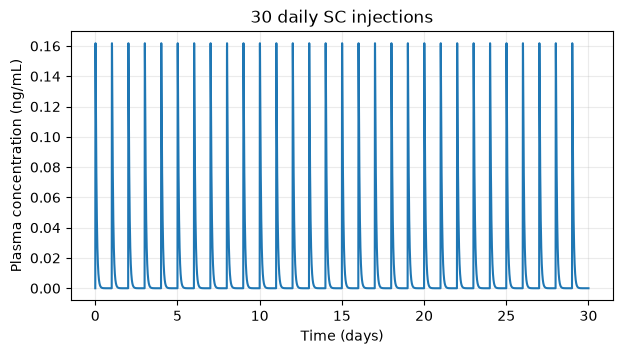

In [3]:
def sc_single(t, dose, F, vd, cl, ka):
    """Plasma concentration after one SC injection."""

    kel = cl / vd                  
    t = np.asarray(t)

    # Absorption and elimination rates are nearly equal
    if np.isclose(ka, kel):
        return (F * dose / vd) * ka * t * np.exp(-kel * t)

    # First-order absorption and elimination
    return (F * dose / vd) * ka / (ka - kel) * (np.exp(-kel * t) - np.exp(-ka * t)
    )


def sc_repeated(t, dose, F, vd, cl, ka, interval, n_doses):
    """Plasma concentration after repeated SC injections."""

    t = np.asarray(t)
    cp = np.zeros_like(t, dtype=float)  # Initial concentration

    for i in range(n_doses):
        elapsed = t - i * interval      # Time since injection
        mask = elapsed >= 0             # Include administered doses only

        # Add concentration from each injection
        cp[mask] += sc_single(elapsed[mask], dose, F, vd, cl, ka)

    return cp


t = np.linspace(0, 30 * 24, 30 * 24 * 60 + 1) # resolution: 1 minute
cp = sc_repeated(t, dose, F, vd, cl, ka, interval, n_doses)

plt.plot(t / 24, cp)
plt.xlabel("Time (days)")
plt.ylabel("Plasma concentration (ng/mL)")
plt.title("30 daily SC injections")
plt.grid(alpha=0.25)
plt.show()

## 4. Zoom: first 2 days

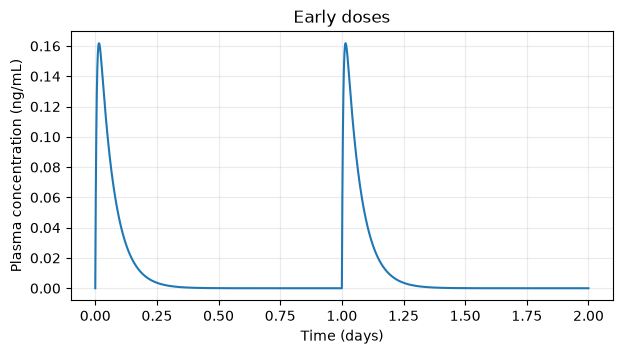

In [4]:
mask = t <= 48
plt.plot(t[mask] / 24, cp[mask])
plt.xlabel("Time (days)")
plt.ylabel("Plasma concentration (ng/mL)")
plt.title("Early doses")
plt.grid(alpha=0.25)
plt.show()

## 5. Daily Cmax, trough and AUC

`Cmax`: peak after each injection. `Cmin`: concentration just before the next dose (each X day). `AUC`: exposure during each 24-hour interval.

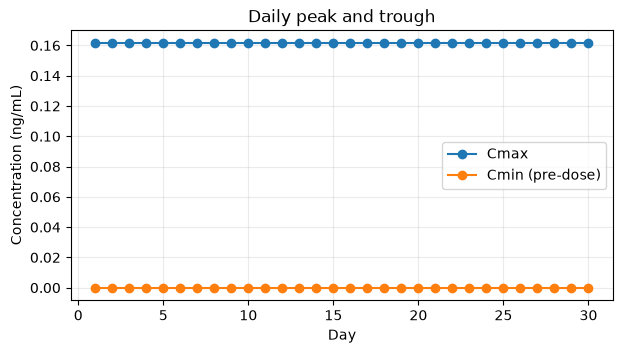

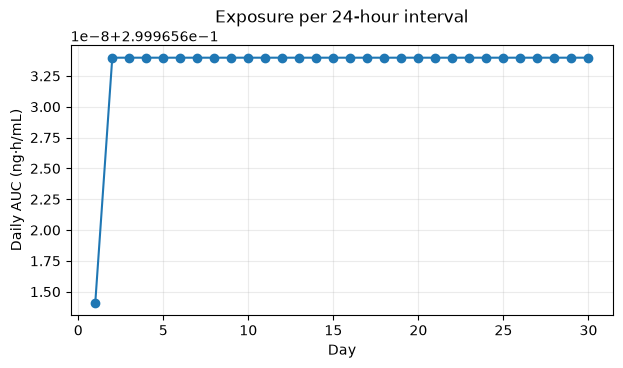

Day 1 AUC: 0.300 ng·h/mL
Day 30 AUC: 0.300 ng·h/mL
Peak ratio (day 30/day 1): 1.000


In [5]:
# Calculate daily PK parameters
days = np.arange(1, n_doses + 1) # til day 30
peaks, troughs, daily_auc = [], [], [] # store results

for day in days:
    start = (day - 1) * interval    # Start of dosing interval
    end = day * interval           # End of dosing interval
    m = (t >= start) & (t <= end)  # Select time points within the day

    peaks.append(cp[m].max())                # Cmax: highest concentration
    troughs.append(cp[m][-1])                # Cmin: concentration at interval end
    daily_auc.append(np.trapezoid(cp[m], t[m]))  # AUC daily

peaks = np.array(peaks)
troughs = np.array(troughs)
daily_auc = np.array(daily_auc)

fig, ax = plt.subplots()
ax.plot(days, peaks, "o-", label="Cmax")
ax.plot(days, troughs, "o-", label="Cmin (pre-dose)")
ax.set(xlabel="Day", ylabel="Concentration (ng/mL)", title="Daily peak and trough")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

plt.plot(days, daily_auc, "o-")
plt.xlabel("Day")
plt.ylabel("Daily AUC (ng·h/mL)")
plt.title("Exposure per 24-hour interval")
plt.grid(alpha=0.25)
plt.show()

print(f"Day 1 AUC: {daily_auc[0]:.3f} ng·h/mL")
print(f"Day 30 AUC: {daily_auc[-1]:.3f} ng·h/mL")
print(f"Peak ratio (day 30/day 1): {peaks[-1]/peaks[0]:.3f}")

## 6. Cumulative exposure

Cumulative AUC over 30 days.

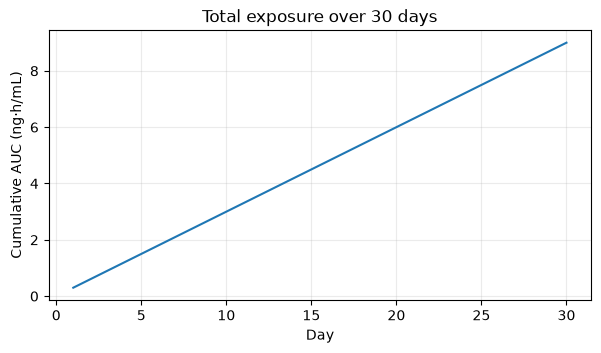

In [6]:
plt.plot(days, np.cumsum(daily_auc))
plt.xlabel("Day")
plt.ylabel("Cumulative AUC (ng·h/mL)")
plt.title("Total exposure over 30 days")
plt.grid(alpha=0.25)
plt.show()

## 7. Population: 100 simulated patients

To look for range selected below.

- Weight: uniform 50–100 kg
- CL: ±20% around 62 L/h
- ka: ±30% around 0.693 h⁻¹
- F: uniform 0.80–0.95

Weight changes Vd and all the rest sampled independently.

In [7]:
# Simulate 100 patients with different PK parameters
rng = np.random.default_rng(42)  # Fixed seed
n_patients = 100 # number of patients

# Parameter values
weights = rng.uniform(50, 100, n_patients)      # Body weight: 50–100 kg
vds = vd_per_kg * weights                       # Distribution volume (L)
cls = cl * rng.uniform(0.8, 1.2, n_patients)    # Clearance: ±20%
kas = ka * rng.uniform(0.7, 1.3, n_patients)    # Absorption rate: ±30%
Fs = rng.uniform(0.80, 0.95, n_patients)        # Bioavailability: 80–95%

# Calculate 30-day concentration profiles for all patients
profiles = np.array([
    sc_repeated(t, dose, Fs[i], vds[i], cls[i], kas[i], interval, n_doses)
    for i in range(n_patients)
])

print("Population profiles:", profiles.shape)

Population profiles: (100, 43201)


In [8]:

# Population parameter ranges
df = pd.DataFrame({
    "Weight (kg)": weights,
    "Vd (L)": vds,
    "CL (L/h)": cls,
    "ka (1/h)": kas,
    "F": Fs
})

summary = pd.DataFrame({
    "Min": df.min(),
    "Mean": df.mean(),
    "Max": df.max(),
    "SD": df.std()
})

display(summary.round(2))

,Min,Mean,Max,SD
Weight (kg),50.37,74.34,98.78,13.68
Vd (L),6.04,8.92,11.85,1.64
CL (L/h),48.52,60.02,71.82,7.01
ka (1/h),0.49,0.68,0.89,0.13
F,0.80,0.88,0.95,0.04


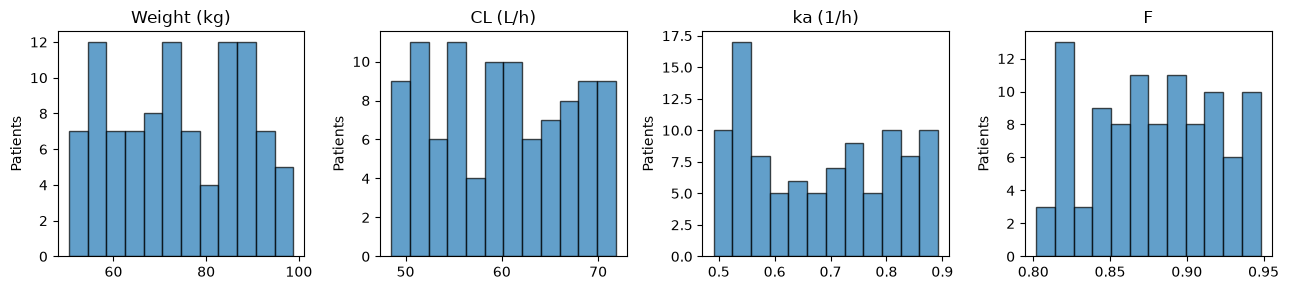

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))

for ax, col in zip(axes, ["Weight (kg)", "CL (L/h)", "ka (1/h)", "F"]):
    ax.hist(df[col], bins=12, edgecolor="black", alpha=0.7)
    ax.set_title(col)
    ax.set_ylabel("Patients")

plt.tight_layout()
plt.show()

## 8. Population concentration plots

30-day overview, then a zoom into the last two days. Shaded region: 2.5th–97.5th percentiles of simulated concentrations

/home/ali/miniforge3/envs/bone-pkpd/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


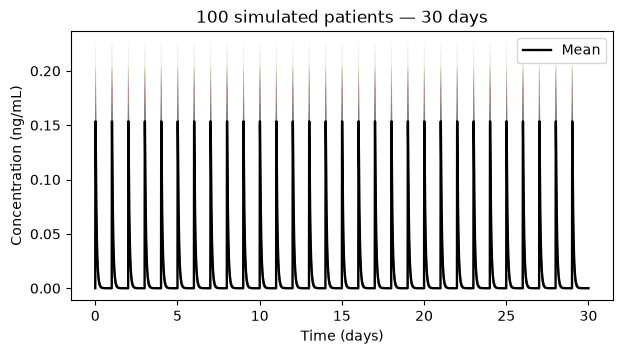

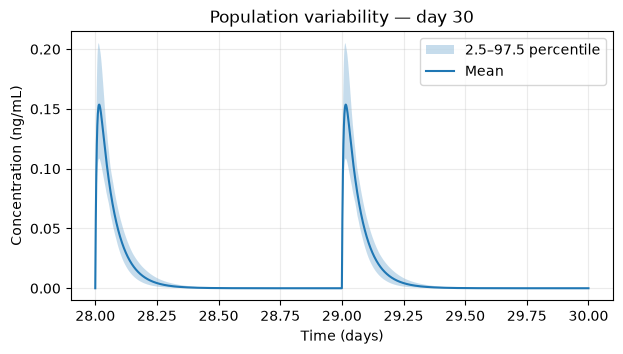

In [10]:
mean_cp = profiles.mean(axis=0)
low_cp, high_cp = np.percentile(profiles, [2.5, 97.5], axis=0) # percentiles

plt.plot(t / 24, profiles.T, alpha=0.06, linewidth=0.6)
plt.plot(t / 24, mean_cp, color="black", linewidth=1.7, label="Mean")
plt.xlabel("Time (days)")
plt.ylabel("Concentration (ng/mL)")
plt.title("100 simulated patients — 30 days")
plt.legend()
plt.show()

last = t >= 28 * 24 # day 28 to 30
plt.fill_between(t[last] / 24, low_cp[last], high_cp[last], alpha=0.25,
                 label="2.5–97.5 percentile")
plt.plot(t[last] / 24, mean_cp[last], label="Mean")
plt.xlabel("Time (days)")
plt.ylabel("Concentration (ng/mL)")
plt.title("Population variability — day 30")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 9. Compare exposure across patients

Calculate each patient's Cmax, Tmax and AUC on day 30.

Cmax: 0.155 ± 0.028 ng/mL (mean ± SD)
Tmax: -1417.080 ± 3.971 min (mean ± SD)
AUC day 30: 0.594 ± 0.075 ng·h/mL (mean ± SD)


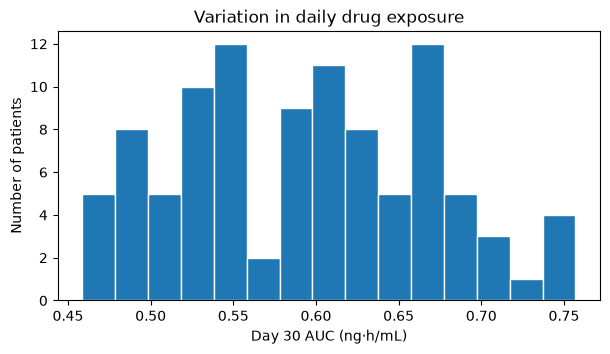

In [11]:
# Day 30 concentration profiles
t_last = t[last]               # Time points on day 30
p_last = profiles[:, last]     # Concentrations for all patients

# Calculate PK parameters for each patient last day!
patient_cmax = p_last.max(axis=1)                         # Peak concentration (ng/mL)
patient_tmax = (t_last[np.argmax(p_last, axis=1)] - 29 * 24) * 60  # Time to peak (min)
patient_auc = np.trapezoid(p_last, t_last, axis=1)         # Daily drug exposure

# Population statistics (mean ± SD)
for name, values, unit in [
    ("Cmax", patient_cmax, "ng/mL"),
    ("Tmax", patient_tmax, "min"),
    ("AUC day 30", patient_auc, "ng·h/mL"),
]:
    print(f"{name}: {values.mean():.3f} ± {values.std(ddof=1):.3f} {unit} (mean ± SD)")

plt.hist(patient_auc, bins=15, edgecolor="white")
plt.xlabel("Day 30 AUC (ng·h/mL)")
plt.ylabel("Number of patients")
plt.title("Variation in daily drug exposure")
plt.show()

# Clustering patients

## silhouette_score is a metric to evaluate the quality of a clustering. It measures how dense and well-separated the generated clusters are by outputting a score between -1 and +1.

In [12]:
# Group patients based on Cmax, Tmax, and AUC
X = np.column_stack([patient_cmax, patient_tmax, patient_auc]) # stack features into a matrix
X_scaled = StandardScaler().fit_transform(X)  # Standardize variables

# Find the best number of clusters (2–8)
scores = []

for k in range(2, 9): # Test 2 to 8 clusters
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, labels))

best_k = np.argmax(scores) + 2  # Number with highest silhouette score
print(f"Best number of clusters: {best_k}")

# Assign patients to clusters
model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
groups = model.fit_predict(X_scaled)

# Evaluate cluster separation
score = silhouette_score(X_scaled, groups) # score ranges from -1 (poor) to +1 (good)
print(f"Silhouette score: {score:.3f}")

# Store patient results
results = pd.DataFrame({
    "Group": groups,
    "Cmax": patient_cmax,
    "Tmax": patient_tmax,
    "AUC": patient_auc
})

# Compare average PK outcomes between clusters
display(results.groupby("Group").agg(
    Patients=("AUC", "size"),
    Cmax=("Cmax", "mean"),
    Tmax=("Tmax", "mean"),
    AUC=("AUC", "mean")
).round(3))

Best number of clusters: 3
Silhouette score: 0.379


,Patients,Cmax,Tmax,AUC
Group,,,,
0,28,0.189,-1417.929,0.648
1,29,0.145,-1412.379,0.645
2,43,0.140,-1419.698,0.524


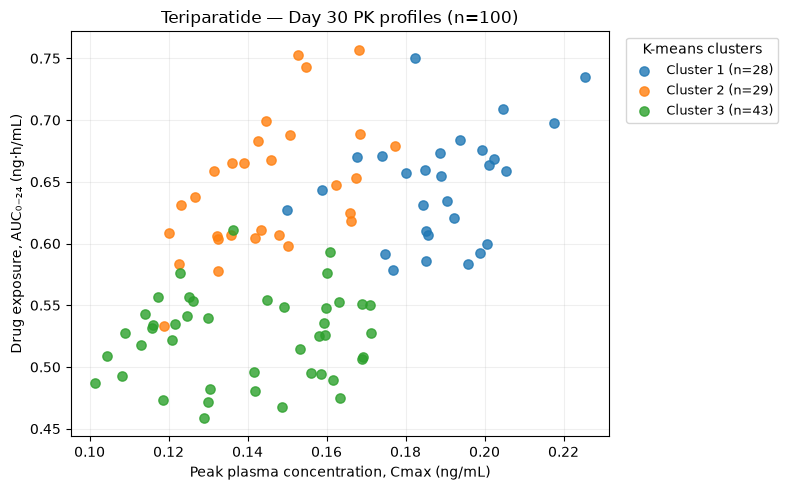

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

for g in np.unique(groups):
    mask = groups == g

    ax.scatter(
        patient_cmax[mask],
        patient_auc[mask],
        s=45,
        alpha=0.8,
        label=f"Cluster {g + 1} (n={mask.sum()})"
    )

ax.set_xlabel("Peak plasma concentration, Cmax (ng/mL)")
ax.set_ylabel("Drug exposure, AUC₀₋₂₄ (ng·h/mL)")
ax.set_title(f"Teriparatide — Day 30 PK profiles (n={len(groups)})")

ax.legend(
    title="K-means clusters",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 10. Notes

- Daily plasma peaks repeat.
- Patient-to-patient variation changes the height and timing of the curves.
